In [14]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv

#加载.env文件中的环境变量
load_dotenv()

#创建模型
model = init_chat_model("gpt-4o")

In [15]:
# 添加一个天气查询的工具
from langchain.tools import tool
@tool
def weather_query(location:str):
    """根据地址获取当前天气"""
    return f"今天{location}天气晴朗，气温25度"

In [16]:
#创建智能体
agent = create_agent(
    model=model,
    tools=[weather_query],
)

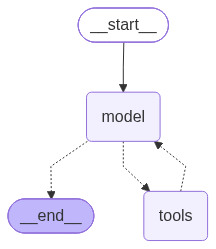

In [17]:
agent

In [18]:
# 1、直接调用智能体， 等待处理后的结果
result = agent.invoke({
    "messages":[
        {"role":"user","content":"今天上海天气怎么样？"}
    ]
})

In [19]:
result

{'messages': [HumanMessage(content='今天上海天气怎么样？', additional_kwargs={}, response_metadata={}, id='33698354-c062-4526-9e1d-4f1281009dc4'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 48, 'total_tokens': 62, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o', 'system_fingerprint': 'fp_4021733588', 'id': 'chatcmpl-EZ0pbEoSTIIlPBI5CR7HhaiH1rpzW', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a13c52-2b80-76f3-a45d-f2cbc228802f-0', tool_calls=[{'name': 'weather_query', 'args': {'location': '上海'}, 'id': 'call_Y92MUVUkICJ8k3fbkbIkm7a0', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadat

In [20]:
# 2、以流式方式输出，每处理完一个chunk就输出一次
for chunk in agent.stream(
        {
            "messages":[
                {"role":"user","content":"今天上海天气怎么样？"}
            ]
    }, stream_mode="updates"
):
    for key, value in chunk.items():
        print(f"{key}: {value["messages"][-1].content}") # 输出每个chunk中的content内容

model: 
tools: 今天上海天气晴朗，气温25度
model: 今天上海天气晴朗，气温25度，非常适合外出活动！


In [21]:
# 2、以流式方式输出，每处理完一个chunk就输出一次
for chunk,metadata in agent.stream(
        {
            "messages":[
                {"role":"user","content":"今天上海天气怎么样？并详细解释什么是人工智能！"}
            ]
    }, stream_mode="messages"
):
    # Agent的底层其实就是LangGraph的图结构，就是由一个节点一个节点构成。
    if metadata["langgraph_node"] == "model": #只显示模型节点处理后的内容
        print(chunk.content, end="", flush=True) # 输出每个chunk中的content内容

今天上海的天气很晴朗，气温为25度，非常适合外出活动。

至于“人工智能” (Artificial Intelligence, 简称 AI)，它是计算机科学的一个分支，目标是让机器拥有模拟人类智能的能力。以下是一个详尽的解释：

### 什么是人工智能？
人工智能是关于设计和开发用于执行通常需要人类智能的任务的系统或机器的学科。这些任务可以包括学习、推理、规划、问题解决、感知、语言理解和生成等。

### 基础原理
1. **学习**: 机器可以通过经验、示例或数据分析学习如何执行某些任务，这被称为“机器学习”。
2. **推理**: AI 系统能够基于可用的信息进行推理，推导出结论或预测未来的情况。
3. **自然语言处理**: AI 可以帮助实现与人的语言交流，例如理解语音指令或生成自然的书面回答。
4. **感知**: 通过传感器或摄像头，AI 也可以感知外部环境，例如识别图像、判断声音等。

### 类型
人工智能根据能力可以分为以下几类：
1. **弱人工智能 (Narrow AI)**: 专注于特定任务，适用于单一领域的应用，例如语音助手、推荐系统等。
2. **强人工智能 (General AI)**: 能够灵活地应对任何类型的任务，和人类一样能够思考和学习，目前仍是研究目标。
3. **超级人工智能 (Super AI)**: 超越人类智能的假想未来形态。

### 应用领域
AI 已广泛用于各种行业，如医疗（辅助诊断、药物开发）、金融（风险预测、欺诈检测）、交通（自动驾驶）、教育（个性化学习）等。

### 挑战与争议
1. **道德问题**: 包括隐私泄露、无偏性、不公平对待等问题。
2. **控制和安全**: 如何确保 AI 行为在可控范围内。
3. ** 社会影响**: 自动化可能替代部分工作岗位，需要社会做出调整。

希望这个解释能帮助你更好地理解人工智能的概念及其重要性！如果你还有其他问题，随时可以问我哦！

In [22]:
## 自定义输出
# 添加一个天气查询的工具,并在工具在执行的过程，自定义输出
from langchain.tools import tool
from langgraph.config import get_stream_writer
@tool
def get_current_weather(location:str):
    """根据地址获取当前天气"""
    out = get_stream_writer()
    out(f"工具正在执行中，查询{location}的天气...") # 自定义输出
    return f"今天{location}天气晴朗，气温25度"

In [23]:
agent = create_agent(
    model=model,
    tools=[get_current_weather],
)

In [24]:
# 2、以流式方式输出，每处理完一个chunk就输出一次
for stream_mode, chunk in agent.stream(
        {
            "messages":[
                {"role":"user","content":"今天上海天气怎么样？并详细解释什么是人工智能！"}
            ]
    }, 
    stream_mode=["custom", "updates"] #如果使用自定义输出，则只有自定义的内容输出，其他内容是不输出的。所以，custom模型一般会和其他模型组合使用
):
    if stream_mode == "custom":
        print(chunk)
    elif stream_mode == "updates":
        for key, value in chunk.items():
            print(f"{key}: {value['messages'][-1].content}") # 输出每个chunk中的content内容

model: 
工具正在执行中，查询上海的天气...
tools: 今天上海天气晴朗，气温25度
model: 今天上海的天气是晴朗的，气温25度，非常适合进行户外活动。

### 什么是人工智能（AI）？
人工智能（Artificial Intelligence，简称 AI）是指通过计算机系统模拟人类智能的技术。它试图让机器能够像人类一样思考、学习和解决问题。这是一门跨学科的领域，结合了计算机科学、数学、统计学和认知科学等不同学科的知识。

### 人工智能的工作原理
人工智能的核心是算法和数据。它通过两大主要方式来实现智能功能：
1. **机器学习**：这是人工智能的一个重要分支，是通过分析大量数据并找到模式，从而使机器做出智能决策的技术。例如，推荐系统会根据用户的历史购买记录来建议商品。
2. **深度学习**：这是机器学习的一个子领域，使用模拟人类大脑模式的神经网络来解决复杂问题，例如图像识别和语音处理。

### 人工智能的类型
人工智能通常分为以下几类：
1. **弱人工智能**：专注于完成特定任务，例如语音助手、推荐系统等。
2. **强人工智能**：具备与人类相当的学习能力和思维能力，能够胜任广泛的任务（目前尚未实现）。
3. **超人工智能**：超越人类智能的人工智能，这属于理论探讨阶段。

### 人工智能的应用
人工智能在多个领域有广泛应用，例如：
- **医疗领域**：用于疾病诊断、个性化药物开发等。
- **交通领域**：无人驾驶汽车、导航系统。
- **娱乐领域**：个性化内容推荐、特效制作。
- **金融领域**：金融欺诈检测、投资建议。

### 未来的人工智能
未来，人工智能有可能进一步改变人类生活方式，使通讯更高效、生活更便捷，但同时也带来了对隐私和伦理的担忧。

希望以上解释能让你对人工智能有清晰的理解！有任何不明白的地方，欢迎继续提问！


In [25]:
# 异步流式输出,当前代码块以异步方式执行
# 2、以流式方式输出，每处理完一个chunk就输出一次
async for chunk,metadata in agent.astream(
        {
            "messages":[
                {"role":"user","content":"今天上海天气怎么样？并详细解释什么是人工智能！"}
            ]
    }, stream_mode="messages"
):
    # Agent的底层其实就是LangGraph的图结构，就是由一个节点一个节点构成。
    if metadata["langgraph_node"] == "model": #只显示模型节点处理后的内容
        print(chunk.content, end="", flush=True) # 输出每个chunk中的content内容

今天上海的天气晴朗，气温为25度。非常适合外出活动！

接下来，让我为您详细解释什么是人工智能（Artificial Intelligence，简称AI）：

### 什么是人工智能？
人工智能是通过计算机科学和工程技术，让机器具有模仿人类智能的能力。简单来说，人工智能指的是一种能够执行通常需要人类智慧的任务的技术。包括但不限于感知、学习、推理、决策和语言理解。

---

### 人工智能的主要分支
1. **机器学习（Machine Learning）**：
   - 是人工智能的一个子领域，通过让机器从数据中学习，而不需要显式地编程。
   - 包括监督学习（带标签数据训练）、无监督学习（自动发现数据结构）和强化学习（通过试错进行改进）。

2. **自然语言处理（Natural Language Processing, NLP）**：
   - 研究如何让机器理解、生成和与自然语言（比如中文、英语）互动。
   - 应用包括翻译（如 Google Translate）、语音助手（如 Siri）等。

3. **计算机视觉（Computer Vision）**：
   - 让机器拥有像人类一样的视觉能力，能够从图像或视频中识别和理解内容。
   - 用途如自动驾驶、面部识别、医疗影像诊断等。

4. **深度学习（Deep Learning）**：
   - 从神经网络发展而来，特别适用于处理大规模数据任务，是机器学习的一种高级形式。

5. **机器人学（Robotics）**：
   - 结合机械学和人工智能，开发能感知环境并执行复杂任务的机器人。

---

### 人工智能的典型功能
- **感知能力**： 模拟人类的视觉、听觉、触觉等能力，例如图片识别、语音识别。
- **决策能力**： 通过大数据分析进行有效决策，例如推荐系统。
- **自动化任务**： 例如无人驾驶汽车，根据实时情况自行驾驶。

---

### 人工智能的实际应用
1. **日常生活：** 智能语音助手、智能翻译工具、推荐算法（如抖音、Netflix）。
2. **医疗领域：** 诊断疾病（例如基于影像的肿瘤检测）。
3. **金融领域：** 欺诈检测、智能理财。
4. **工业领域：** 自动化生产线中的机器人。
5. **交通运输：** 自动驾驶汽车、交通优化。

---


Failed to send compressed multipart ingest: Connection error caused failure to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. Please confirm your internet connection. ConnectionError(MaxRetryError('HTTPSConnectionPool(host=\'api.smith.langchain.com\', port=443): Max retries exceeded with url: /runs/multipart (Caused by ReadTimeoutError("HTTPSConnectionPool(host=\'api.smith.langchain.com\', port=443): Read timed out. (read timeout=3)"))'))
Content-Length: 1589
API Key: lsv2_********************************************3etrace=01a13c52-2b7c-7530-9bf8-59f0735f75d3,id=01a13c52-2b7c-7530-9bf8-59f0735f75d3; trace=01a13c52-2b7c-7530-9bf8-59f0735f75d3,id=01a13c52-2b7e-7cd0-bbcf-1b0c4d6632cd; trace=01a13c52-2b7c-7530-9bf8-59f0735f75d3,id=01a13c52-2b80-76f3-a45d-f2cbc228802f
Failed to send compressed multipart ingest: Connection error caused failure to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. Please confirm your internet connection. ConnectionEr